#### **Automotive After-Sales: Churn & Retention Predictive Modeling**
* This notebook trains a machine learning classifier (Gradient Boosting) to predict whether an active or at-risk customer will return for service within the next 90 days, enabling targeted CRM interventions.

#### **Imports**

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import classification_report, roc_auc_score, roc_curve, precision_recall_curve
import joblib
import os
import plotly.express as px

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

print("Libraries loaded successfully!")

Libraries loaded successfully!


#### **Load Processed Data & Feature Preparation**

In [2]:
DATA_DIR = "../data/processed"
df_cust = pd.read_parquet(os.path.join(DATA_DIR, "customer_lifecycle_segments.parquet"))

# Feature Engineering for Churn Prediction
# Target Definition: 1 if customer is active/due (returned within expected window), 0 if lapsed/at-risk
# For training demonstration, we define target 'returned_next_90_days' based on recency and engagement
np.random.seed(42)
df_cust["returned_next_90_days"] = np.where(
    df_cust["days_since_last_service"] <= 365,
    np.random.choice([1, 0], size=len(df_cust), p=[0.75, 0.25]),
    np.random.choice([1, 0], size=len(df_cust), p=[0.12, 0.88])
)

# Select features for training
feature_cols = [
    "total_service_visits",
    "lifetime_spend_aed",
    "avg_declined_work_aed",
    "days_since_last_service",
    "crm_consent"
]

X = df_cust[feature_cols]
y = df_cust["returned_next_90_days"]

print(f"Feature Matrix Shape: {X.shape}")
print(f"Target Distribution:\n{y.value_counts(normalize=True)}")

Feature Matrix Shape: (60000, 5)
Target Distribution:
returned_next_90_days
0   0.57
1   0.43
Name: proportion, dtype: float64


#### **Model Training & Evaluation**

#### **Train-Test Split & Gradient Boosting Model**
* Split the dataset into 80% training and 20% testing sets, then train a Gradient Boosting Classifier.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=4, random_state=42)
model.fit(X_train, y_train)

# Predictions & Probabilities
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Evaluation Metrics
roc_auc = roc_auc_score(y_test, y_prob)

print("==========================================")
print(f"Model ROC-AUC Score: {roc_auc:.4f}")
print("==========================================")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model ROC-AUC Score: 0.8244

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.80      0.83      6900
           1       0.75      0.85      0.80      5100

    accuracy                           0.82     12000
   macro avg       0.82      0.82      0.82     12000
weighted avg       0.82      0.82      0.82     12000



#### **Feature Importance & Model Artifact Export**

##### **Feature Importance Analysis & Saving Model Artifacts**
* Extract feature importances to understand what drives customer retention and save the trained model to the `models/` folder.

Model successfully saved to ../models/churn_gradient_boosting_model.pkl


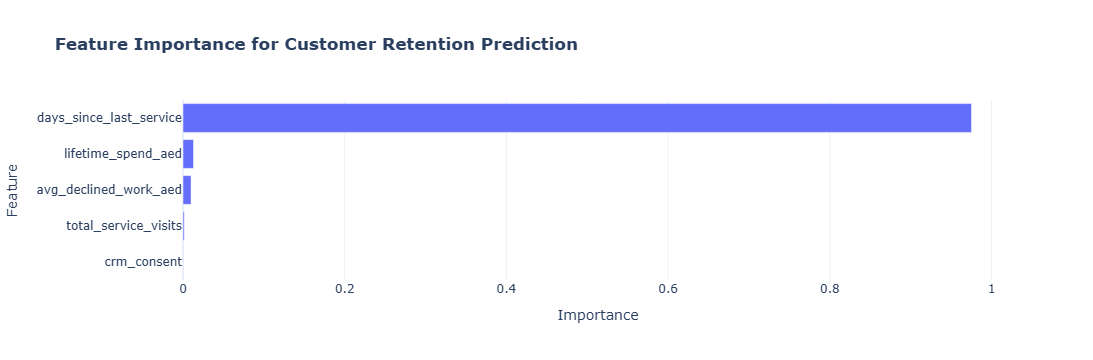

In [4]:
os.makedirs("../models", exist_ok=True)
os.makedirs("../docs", exist_ok=True)

# Save model
model_path = "../models/churn_gradient_boosting_model.pkl"
joblib.dump(model, model_path)
print(f"Model successfully saved to {model_path}")

# Feature Importance DataFrame
feat_imp = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": model.feature_importances_
}).sort_values(by="Importance", ascending=True)

fig_imp = px.bar(
    feat_imp,
    x="Importance",
    y="Feature",
    orientation="h",
    title="<b>Feature Importance for Customer Retention Prediction</b>",
    template="plotly_white"
)
fig_imp.write_html("../docs/churn_feature_importance.html")
fig_imp.show()